In [1]:
#pip install pandas

# Import libraries
import numpy as np
import pandas as pd

In [27]:
#/project2/pishgar_1407/anijjar/mimic-iii-clinical-database-1.4
#hosp_path = '/project2/pishgar_1407/anijjar/mimic-iii-clinical-database-1.4/hosp/'
#icu_path  = '/project2/pishgar_1407/anijjar/mimic-iii-clinical-database-1.4/icu/'
#core_path = '/project2/pishgar_1407/anijjar/mimic-iii-clinical-database-1.4/core/'
#patient = '/project2/pishgar_1407/anijjar/mimic-iii-clinical-database-1.4/PATIENTS.csv.gz'
#ICUstay = '/project2/pishgar_1407/anijjar/mimic-iii-clinical-database-1.4/ICUSTAYS.csv.gz'
#diagnose = '/project2/pishgar_1407/anijjar/mimic-iii-clinical-database-1.4/DIAGNOSES_ICD.csv.gz'
# Read data
path = '/project2/pishgar_1407/anijjar/mimic-iii-clinical-database-1.4'

patient = pd.read_csv('/project2/pishgar_1407/anijjar/mimic-iii-clinical-database-1.4/patients3.csv')
data2 = pd.read_csv('/project2/pishgar_1407/anijjar/mimic-iii-clinical-database-1.4/ICUSTAYS.csv.gz')
diag = pd.read_csv('/project2/pishgar_1407/anijjar/mimic-iii-clinical-database-1.4/DIAGNOSES_ICD.csv.gz')


In [28]:
#data2['FIRST_CAREUNIT'].value_counts()
data2.isnull().sum()

ROW_ID             0
SUBJECT_ID         0
HADM_ID            0
ICUSTAY_ID         0
DBSOURCE           0
FIRST_CAREUNIT     0
LAST_CAREUNIT      0
FIRST_WARDID       0
LAST_WARDID        0
INTIME             0
OUTTIME           10
LOS               10
dtype: int64

In [29]:
data2 = data2.dropna(subset=['OUTTIME'])

In [30]:
patient = patient.drop(columns=['ROW_ID', 'DOB', 'DOD_SSN', 'EXPIRE_FLAG', 'DOB_year', 'DOD_year', 'age_at_death', 'anchor_year_group'])
data2 = data2.drop(columns=['ROW_ID', 'DBSOURCE', 'LAST_WARDID', 'FIRST_WARDID'])

In [31]:
#patients admitting in SICU
data_sicu = data2[data2['FIRST_CAREUNIT']=='SICU']

#sorting them and keeping only first time admits
data_sicu_sort = data_sicu.sort_values(by=['SUBJECT_ID', 'INTIME']).drop_duplicates(subset='SUBJECT_ID', keep='first')

#Merging the patients and icustays
data_merge = patient.merge(data_sicu_sort, on='SUBJECT_ID')

In [6]:
data_merge

,SUBJECT_ID,GENDER,DOD,DOD_HOSP,anchor_year,anchor_age,HADM_ID,ICUSTAY_ID,FIRST_CAREUNIT,LAST_CAREUNIT,INTIME,OUTTIME,LOS
0,256,M,NaN,NaN,2086.0,0.0,155415,295852,SICU,SICU,2163-07-26 20:57:00,2163-07-27 21:53:00,1.0389
1,267,F,NaN,NaN,2131.0,0.0,163714,223660,SICU,SICU,2156-06-04 05:09:29,2156-06-08 15:34:34,4.4341
2,695,F,2178-09-16,NaN,2093.0,0.0,154201,200423,SICU,CSRU,2176-07-07 17:02:00,2176-07-11 21:53:00,4.2021
3,698,F,2168-04-22,NaN,1864.0,0.0,108234,230795,SICU,SICU,2164-11-16 21:35:35,2164-11-17 17:19:00,0.8218
4,711,M,2185-05-26,NaN,2100.0,0.0,114791,281850,SICU,CSRU,2184-05-25 21:14:05,2184-05-26 13:02:05,0.6583
...,...,...,...,...,...,...,...,...,...,...,...,...,...
7690,44036,F,NaN,NaN,2132.0,0.0,170297,239249,SICU,MICU,2186-08-22 03:24:47,2186-08-25 13:53:43,3.4368
7691,44061,M,NaN,NaN,2073.0,0.0,181541,235000,SICU,SICU,2136-08-15 20:41:57,2136-08-16 19:01:54,0.9305
7692,44083,M,2114-02-20,2/20/2114 0:00,2057.0,0.0,125157,265615,SICU,SICU,2112-05-04 19:03:39,2112-05-06 17:21:01,1.9287
7693,44115,F,NaN,NaN,2124.0,0.0,163623,264947,SICU,SICU,2161-07-15 17:16:25,2161-07-16 13:21:38,0.8370


In [32]:
#calculating age using anchorage and anchor_year
data_merge['INTIME'] = pd.to_datetime(data_merge['INTIME'], errors='coerce')
data_merge['anchor_year'] = data_merge['anchor_year'].astype(int)

data_merge['age'] = data_merge['anchor_age'] + ((data_merge['INTIME']).dt.year - data_merge['anchor_year'])

#Excluding patients who are <55 years
data_final = data_merge[data_merge['age'] >= 55].copy()

data_final['age'] = data_final['age'].apply(lambda x: 90 if x > 89 else x)

data_final

,SUBJECT_ID,GENDER,DOD,DOD_HOSP,anchor_year,anchor_age,HADM_ID,ICUSTAY_ID,FIRST_CAREUNIT,LAST_CAREUNIT,INTIME,OUTTIME,LOS,age
0,256,M,NaN,NaN,2086,0.0,155415,295852,SICU,SICU,2163-07-26 20:57:00,2163-07-27 21:53:00,1.0389,77.0
2,695,F,2178-09-16,NaN,2093,0.0,154201,200423,SICU,CSRU,2176-07-07 17:02:00,2176-07-11 21:53:00,4.2021,83.0
3,698,F,2168-04-22,NaN,1864,0.0,108234,230795,SICU,SICU,2164-11-16 21:35:35,2164-11-17 17:19:00,0.8218,90.0
4,711,M,2185-05-26,NaN,2100,0.0,114791,281850,SICU,CSRU,2184-05-25 21:14:05,2184-05-26 13:02:05,0.6583,84.0
6,732,F,2109-01-24,NaN,2041,0.0,189222,263518,SICU,SICU,2108-01-16 21:05:29,2108-01-17 00:26:10,0.1394,67.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7684,43798,M,2200-12-31,12/31/2200 0:00,2136,0.0,130870,243229,SICU,SICU,2198-06-29 15:00:30,2198-07-06 17:35:30,7.1076,62.0
7685,43814,F,NaN,NaN,2041,0.0,116573,257595,SICU,SICU,2101-08-07 22:33:25,2101-08-08 16:39:41,0.7544,60.0
7686,43870,F,2186-02-12,2/12/2186 0:00,2097,0.0,142633,220671,SICU,CCU,2186-02-09 21:33:54,2186-02-12 04:20:06,2.2821,89.0
7691,44061,M,NaN,NaN,2073,0.0,181541,235000,SICU,SICU,2136-08-15 20:41:57,2136-08-16 19:01:54,0.9305,63.0


In [33]:
#getting all hospital admission id's of the patients
hadm_code = set(data_final["HADM_ID"].tolist())

diag = diag[diag["HADM_ID"].isin(hadm_code)].copy()
diag = diag[diag["SEQ_NUM"]==1].copy()

# ICD-9 prefixes for stroke
stroke_icd9_prefixes = ['430','431','433','434','435', '436']


# Identify stroke rows
v9 = (diag['ICD9_CODE'].str[:3].isin(stroke_icd9_prefixes))

diag['is_stroke'] = v9

In [34]:
#data distribution
diag['is_stroke'].value_counts()

is_stroke
False    4209
True     1123
Name: count, dtype: int64

In [35]:
#Getting the unique subject_id of the stroke patients
stroke = diag.loc[diag['is_stroke'], 'SUBJECT_ID'].unique()
print(f"Shape of the stroke patients: {stroke.shape}")

#Stating each patient whether they are stroke or not stroke
data_final['is_stroke'] = data_final['SUBJECT_ID'].isin(stroke).astype(np.int8)
display(data_final.head())

Shape of the stroke patients: (1123,)


,SUBJECT_ID,GENDER,DOD,DOD_HOSP,anchor_year,anchor_age,HADM_ID,ICUSTAY_ID,FIRST_CAREUNIT,LAST_CAREUNIT,INTIME,OUTTIME,LOS,age,is_stroke
0,256,M,NaN,NaN,2086,0.0,155415,295852,SICU,SICU,2163-07-26 20:57:00,2163-07-27 21:53:00,1.0389,77.0,0
2,695,F,2178-09-16,NaN,2093,0.0,154201,200423,SICU,CSRU,2176-07-07 17:02:00,2176-07-11 21:53:00,4.2021,83.0,0
3,698,F,2168-04-22,NaN,1864,0.0,108234,230795,SICU,SICU,2164-11-16 21:35:35,2164-11-17 17:19:00,0.8218,90.0,0
4,711,M,2185-05-26,NaN,2100,0.0,114791,281850,SICU,CSRU,2184-05-25 21:14:05,2184-05-26 13:02:05,0.6583,84.0,0
6,732,F,2109-01-24,NaN,2041,0.0,189222,263518,SICU,SICU,2108-01-16 21:05:29,2108-01-17 00:26:10,0.1394,67.0,0


In [36]:
data_final = data_final.dropna(axis=0)
data_final

,SUBJECT_ID,GENDER,DOD,DOD_HOSP,anchor_year,anchor_age,HADM_ID,ICUSTAY_ID,FIRST_CAREUNIT,LAST_CAREUNIT,INTIME,OUTTIME,LOS,age,is_stroke
7,735,F,2128-07-04,7/4/2128 0:00,2068,0.0,140547,298103,SICU,SICU,2128-05-27 16:11:00,2128-05-30 04:05:24,2.4961,60.0,0
10,747,M,2147-03-07,3/7/2147 0:00,2063,0.0,130986,230340,SICU,SICU,2147-03-07 11:51:54,2147-03-07 23:56:57,0.5035,84.0,0
12,751,M,2157-07-21,7/21/2157 0:00,2097,0.0,141048,226226,SICU,SICU,2153-02-05 19:00:57,2153-02-07 23:21:25,2.1809,56.0,0
13,752,F,2127-02-28,2/28/2127 0:00,2042,0.0,140333,234921,SICU,SICU,2127-02-27 23:38:42,2127-02-28 21:48:46,0.9237,85.0,0
17,766,F,2178-03-27,3/27/2178 0:00,2092,0.0,183370,288176,SICU,SICU,2178-03-03 23:19:45,2178-03-05 11:40:21,1.5143,86.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7655,79049,F,2154-12-16,12/16/2154 0:00,2078,0.0,187801,234357,SICU,SICU,2154-12-15 02:07:37,2154-12-16 11:48:36,1.4035,76.0,0
7679,43746,F,2111-01-14,1/14/2111 0:00,2029,0.0,167181,289236,SICU,SICU,2111-01-07 16:36:48,2111-01-09 15:47:22,1.9657,82.0,0
7684,43798,M,2200-12-31,12/31/2200 0:00,2136,0.0,130870,243229,SICU,SICU,2198-06-29 15:00:30,2198-07-06 17:35:30,7.1076,62.0,0
7686,43870,F,2186-02-12,2/12/2186 0:00,2097,0.0,142633,220671,SICU,CCU,2186-02-09 21:33:54,2186-02-12 04:20:06,2.2821,89.0,1


In [44]:
#Distribution of stroke patients
print(data_final['is_stroke'].value_counts())

print("Unique values of hadm_id: ", data_final['HADM_ID'].nunique())
print("Unique values of subject_id: ", data_final['SUBJECT_ID'].nunique())

is_stroke
0    1421
1     425
Name: count, dtype: int64
Unique values of hadm_id:  1846
Unique values of subject_id:  1846


In [38]:
cohort = data_final.copy()

print(f"Null values of the dataset: \n{cohort.isnull().sum()}")

Null values of the dataset: 
SUBJECT_ID        0
GENDER            0
DOD               0
DOD_HOSP          0
anchor_year       0
anchor_age        0
HADM_ID           0
ICUSTAY_ID        0
FIRST_CAREUNIT    0
LAST_CAREUNIT     0
INTIME            0
OUTTIME           0
LOS               0
age               0
is_stroke         0
dtype: int64


In [39]:
patients   = pd.read_csv('/project2/pishgar_1407/anijjar/mimic-iii-clinical-database-1.4/patients3.csv', usecols=['SUBJECT_ID','GENDER','anchor_age'])
admissions = pd.read_csv('/project2/pishgar_1407/anijjar/mimic-iii-clinical-database-1.4/ADMISSIONS.csv.gz', usecols=['SUBJECT_ID','HADM_ID','ETHNICITY', 'INSURANCE'])
icustays   = pd.read_csv('/project2/pishgar_1407/anijjar/mimic-iii-clinical-database-1.4/ICUSTAYS.csv.gz', usecols=['SUBJECT_ID','HADM_ID','ICUSTAY_ID','INTIME'])
#/project2/pishgar_1407/anijjar/mimic-iii-clinical-database-1.4

icustays['INTIME'] = pd.to_datetime(icustays['INTIME'])

# Merge demographic info
demo = (patients.merge(admissions, on='SUBJECT_ID', how='left')
                .merge(icustays[['SUBJECT_ID','HADM_ID','ICUSTAY_ID']], on=['SUBJECT_ID','HADM_ID'], how='left'))


In [45]:
diagnoses = pd.read_csv('/project2/pishgar_1407/anijjar/mimic-iii-clinical-database-1.4/DIAGNOSES_ICD.csv.gz',
                        usecols=['SUBJECT_ID','HADM_ID','ICD9_CODE'])

# Define ICD prefixes (short list)
comorb_prefixes = {
    'pvd': (['440','441','442','443','444']),
    'htn': (['401','402','403','404','405']),
    'copd': (['490','491','492','493','494','495','496']),
    'diabetes': (['250']),
    'renal': (['585']),
    'liver': (['570','571','572','573']),
    'pud': (['531','532','533','534']),
    'sepsis': (['038']),
    'chf': (['428']),
    'cancer': ([str(x) for x in range(140,240)]),
    'rheumatic': (['710'])
}
diagnoses['ICD9_CODE'] = diagnoses['ICD9_CODE'].astype(str).str.upper()


for name, icd9 in comorb_prefixes.items():
    diagnoses[name] = np.where(
        diagnoses['ICD9_CODE'].str[:3].isin(icd9),
        1, 0)
comorb = diagnoses.groupby(['SUBJECT_ID','HADM_ID'])[list(comorb_prefixes.keys())].max().reset_index()
display(comorb.head())

,SUBJECT_ID,HADM_ID,pvd,htn,copd,diabetes,renal,liver,pud,sepsis,chf,cancer,rheumatic
0,2,163353,0,0,0,0,0,0,0,0,0,0,0
1,3,145834,0,0,0,0,0,0,0,1,1,0,0
2,4,185777,0,0,0,0,0,1,0,0,0,0,0
3,5,178980,0,0,0,0,0,0,0,0,0,0,0
4,6,107064,1,1,0,0,0,0,0,0,0,0,0


In [46]:
diagn = pd.read_csv('/project2/pishgar_1407/anijjar/mimic-iii-clinical-database-1.4/DIAGNOSES_ICD.csv.gz',
                        usecols=['SUBJECT_ID','HADM_ID','ICD9_CODE'])

addictives={
    'Alcohol': (['30300', '30500', 'V113']), #	Alcohol abuse or dependence
    'Tobacco': (['30501']), #	Tobacco use disorder
    'Opioid': (['30400', '30550']), #	Opioid dependence or use
    'Cannabis': (['30430']), #	Cannabis use
    'Cocaine': (['30420', '30560']), #	Cocaine use
    'Sedative': (['30410', '30540']), #	Sedative use disorder
    'Other': (['30490', '30590']),
    'Smoking': (['Z87891'])
}

diagn['ICD9_CODE'] = diagn['ICD9_CODE'].astype(str).str.upper()


#diagn[diagn['icd_code']=='']#.str.contains("alcohol abuse", case=False, na=False)].sort_values('icd_code')

for name, icd9 in addictives.items():
    diagn[name] = np.where(
        diagn['ICD9_CODE'].str[:3].isin(icd9),
        1, 0)
addict = diagn.groupby(['SUBJECT_ID','HADM_ID'])[list(addictives.keys())].max().reset_index()
addict

,SUBJECT_ID,HADM_ID,Alcohol,Tobacco,Opioid,Cannabis,Cocaine,Sedative,Other,Smoking
0,2,163353,0,0,0,0,0,0,0,0
1,3,145834,0,0,0,0,0,0,0,0
2,4,185777,0,0,0,0,0,0,0,0
3,5,178980,0,0,0,0,0,0,0,0
4,6,107064,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...
58971,99985,176670,0,0,0,0,0,0,0,0
58972,99991,151118,0,0,0,0,0,0,0,0
58973,99992,197084,0,0,0,0,0,0,0,0
58974,99995,137810,0,0,0,0,0,0,0,0


In [47]:
lab_ids = [50931,50868,50862,50885,50912,50810,50811,51301,50813,
           51265,50971,51275,51274,51237,51006, 50970, 50983, 
           50960, 50902, 50893, 50889, 50878, 51003]

icustays = icustays[icustays['ICUSTAY_ID'].isin(cohort['ICUSTAY_ID'])]
icustays_short = icustays[['SUBJECT_ID','HADM_ID','ICUSTAY_ID','INTIME']].copy()
icustays_short['INTIME'] = pd.to_datetime(icustays_short['INTIME'])

chunks = []
cohort_hadm = set(cohort['HADM_ID'])
for chunk in pd.read_csv('/project2/pishgar_1407/anijjar/mimic-iii-clinical-database-1.4/LABEVENTS.csv.gz',
                         usecols=['SUBJECT_ID','HADM_ID','ITEMID','CHARTTIME','VALUENUM'],
                         chunksize=500000):
    chunk = chunk[chunk['HADM_ID'].isin(cohort_hadm)]
    chunk = chunk[chunk['ITEMID'].isin(lab_ids)]
    chunk = chunk.merge(icustays_short, on=['SUBJECT_ID','HADM_ID'], how='inner')
    chunk['CHARTTIME'] = pd.to_datetime(chunk['CHARTTIME'])
    mask = (chunk['CHARTTIME'] >= chunk['INTIME']) & (chunk['CHARTTIME'] <= chunk['INTIME'] + pd.Timedelta(hours=24))
    chunk = chunk.loc[mask]
    #agg = chunk.groupby(['stay_id','itemid'])['valuenum'].agg(['min','max','mean']).reset_index()
    chunks.append(chunk)

lab_summary = pd.concat(chunks, ignore_index=True)
print("Labs processed:", len(lab_summary))

/tmp/SLURM_4977228/ipykernel_1029896/2408935020.py:17: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  chunk['CHARTTIME'] = pd.to_datetime(chunk['CHARTTIME'])


Labs processed: 55719


In [48]:
labs_summary = (
    lab_summary.pivot_table(
        index=['ICUSTAY_ID'],
        columns='ITEMID',
        values='VALUENUM',
        aggfunc=['mean', 'min', 'max']
    ).reset_index()
)
# flatten multi-level columns
#labs_summary.columns = ['_'.join([str(i) for i in col if i]) for col in labs_summary.columns]
#display(labs_summary.head())

In [49]:
labs_summary.rename(columns={
    50810: 'Hematocrit',
    50811: 'Hemoglobin',
    50813: 'Lactate',
    50862: 'Albumin',
    50868: 'Anion Gap',
    50885: 'Bilirubin',
    50912: 'Creatinine',
    50931: 'Glucose',
    50971: 'Potassium',
    51006: 'Urea Nitrogen',
    51237: 'INR(PT)',
    51265: 'Platelet Count',
    51274: 'PT',
    51275: 'PTT',
    51301: 'WBC',
    50970: 'Phosphate',
    50983: 'Na',
    50960: 'Mg',
    50902: 'chloride',
    50893: 'Ca',
    50889: 'CRP',
    50878: 'AST',
    51003: 'Troponin' 
}, inplace=True)

In [50]:

labs_summary.columns = ['ICUSTAY_ID'] + [
    f"{col[0]}_{col[1]}" if isinstance(col, tuple) and col[1] else col[0]
    for col in labs_summary.columns[1:]
    #f"{col}_{stat}" for col, stat in vitals_summary.columns[2:]
]

labs_summary.head()

,ICUSTAY_ID,mean_Hematocrit,mean_Hemoglobin,mean_Lactate,mean_Albumin,mean_Anion Gap,mean_AST,mean_Bilirubin,mean_CRP,mean_Ca,...,max_Phosphate,max_Potassium,max_Na,max_Troponin,max_Urea Nitrogen,max_INR(PT),max_Platelet Count,max_PT,max_PTT,max_WBC
0,200033,NaN,NaN,NaN,NaN,14.0,NaN,NaN,NaN,8.000000,...,3.4,7.5,140.0,NaN,18.0,1.2,165.0,13.9,24.4,11.8
1,200044,NaN,NaN,NaN,3.4,11.0,NaN,NaN,NaN,8.600000,...,2.3,4.2,133.0,NaN,31.0,NaN,283.0,NaN,NaN,10.2
2,200112,NaN,NaN,0.950000,NaN,16.0,NaN,NaN,NaN,8.266667,...,5.0,5.3,140.0,NaN,43.0,3.3,459.0,22.3,39.7,12.7
3,200146,NaN,NaN,NaN,NaN,13.0,NaN,NaN,NaN,9.100000,...,4.0,4.1,139.0,NaN,37.0,NaN,237.0,NaN,NaN,6.8
4,200185,25.5,8.5,3.133333,NaN,16.0,NaN,NaN,NaN,8.400000,...,2.6,3.9,135.0,NaN,8.0,1.1,274.0,12.6,43.9,10.4


In [51]:
vital_ids = [220045,220179,220180,220181,220277]

chunks = []

for chunk in pd.read_csv('/project2/pishgar_1407/anijjar/mimic-iii-clinical-database-1.4/CHARTEVENTS.csv.gz',
                         usecols=['SUBJECT_ID','HADM_ID','ITEMID','CHARTTIME','VALUENUM'],
                         chunksize=500000):
    chunk = chunk[chunk['HADM_ID'].isin(cohort_hadm)]
    chunk = chunk[chunk['ITEMID'].isin(vital_ids)]
    chunk = chunk.merge(icustays_short, on=['SUBJECT_ID','HADM_ID'], how='inner')
    chunk['CHARTTIME'] = pd.to_datetime(chunk['CHARTTIME'])
    mask = (chunk['CHARTTIME'] >= chunk['INTIME']) & (chunk['CHARTTIME'] <= chunk['INTIME'] + pd.Timedelta(hours=24))
    chunk = chunk.loc[mask]
    chunks.append(chunk)

vital_summary = pd.concat(chunks, ignore_index=True)
print("Vitals processed:", len(vital_summary))

Vitals processed: 76245


In [52]:
vital_summary.head()

,SUBJECT_ID,HADM_ID,ITEMID,CHARTTIME,VALUENUM,ICUSTAY_ID,INTIME
0,357,117876,220277,2199-12-24 23:00:00,100.0,235292,2199-12-24 19:52:27
1,357,117876,220045,2199-12-25 00:00:00,79.0,235292,2199-12-24 19:52:27
2,357,117876,220277,2199-12-25 00:00:00,100.0,235292,2199-12-24 19:52:27
3,357,117876,220179,2199-12-25 00:01:00,104.0,235292,2199-12-24 19:52:27
4,357,117876,220180,2199-12-25 00:01:00,65.0,235292,2199-12-24 19:52:27


In [53]:
vitals_summary = (
    vital_summary.pivot_table(
        index=['ICUSTAY_ID'],
        columns='ITEMID',
        values='VALUENUM',
        aggfunc=['max', 'mean', 'min']
    ).reset_index()
)

In [54]:
vitals_summary.rename(columns={
    220045: 'Heart Rate',
    220179: 'systolic_BP',
    220180: 'diastolic_BP',
    220181: 'mean_BP',
    220277: 'Spo2'
}, inplace=True)

In [55]:
vitals_summary.columns = ['ICUSTAY_ID'] + [
    f"{col[0]}_{col[1]}" if isinstance(col, tuple) else col
    for col in vitals_summary.columns[1:]
    #f"{col}_{stat}" for col, stat in vitals_summary.columns[2:]
]

In [56]:
vitals_summary.head()

,ICUSTAY_ID,max_Heart Rate,max_systolic_BP,max_diastolic_BP,max_mean_BP,max_Spo2,mean_Heart Rate,mean_systolic_BP,mean_diastolic_BP,mean_mean_BP,mean_Spo2,min_Heart Rate,min_systolic_BP,min_diastolic_BP,min_mean_BP,min_Spo2
0,200033,100.0,123.0,94.0,98.0,96.0,73.260870,111.727273,68.863636,78.954545,94.913043,60.0,103.0,63.0,72.0,94.0
1,200613,104.0,206.0,122.0,126.0,100.0,93.250000,150.925926,63.555556,84.370370,99.714286,78.0,93.0,31.0,51.0,99.0
2,200699,110.0,150.0,70.0,91.0,100.0,98.821429,129.857143,60.857143,77.571429,99.000000,86.0,104.0,56.0,67.0,84.0
3,200861,109.0,84.0,58.0,63.0,100.0,80.760000,84.000000,58.000000,63.000000,96.720000,61.0,84.0,58.0,63.0,79.0
4,200919,101.0,165.0,125.0,132.0,100.0,52.541667,115.578947,50.210526,66.578947,99.954545,0.0,67.0,36.0,43.0,99.0


In [57]:
press = pd.read_csv(path + '/PRESCRIPTIONS.csv.gz', low_memory=False)

press['DRUG'] = press['DRUG'].str.lower()

drug_classes = {
    'anticoagulant': ['warfarin','heparin','enoxaparin','apixaban','rivaroxaban','dabigatran'],
    'aspirin': ['aspirin','clopidogrel','ticagrelor','prasugrel'],
    'statin': ['atorvastatin','simvastatin','rosuvastatin','pravastatin','lovastatin','pitavastatin'],
    'insulin': ['insulin','metformin','glipizide','glyburide','sitagliptin','liraglutide']
}

# Create flags
for cls, keywords in drug_classes.items():
    pattern = '|'.join(keywords)
    press[cls] = press['DRUG'].str.contains(pattern, case=False, na=False).astype(int)

In [32]:
#proced = pd.read_csv(path + '/PROCEDURES_ICD.csv.gz')
#press.head()

In [30]:
"""proced = pd.read_csv(path + '/PROCEDURES_ICD.csv.gz')

# For simplicity, assume we have a datetime column 'chartdate'
# Merge to get operation time per hadm_id
first_op = proced.groupby('HADM_ID')['CHARTDATE'].min().reset_index().rename(columns={'CHARTDATE':'op_time'})

# Merge and filter prescriptions before operation
presc = press.merge(first_op, on='HADM_ID', how='left')
presc_preop = press[press['STARTTIME'] < presc['op_time']]
"""

"proced = pd.read_csv(path + '/PROCEDURES_ICD.csv.gz')\n\n# For simplicity, assume we have a datetime column 'chartdate'\n# Merge to get operation time per hadm_id\nfirst_op = proced.groupby('HADM_ID')['CHARTDATE'].min().reset_index().rename(columns={'CHARTDATE':'op_time'})\n\n# Merge and filter prescriptions before operation\npresc = press.merge(first_op, on='HADM_ID', how='left')\npresc_preop = press[press['STARTTIME'] < presc['op_time']]\n"

In [58]:
preop_flags = (
    press.groupby(['SUBJECT_ID','HADM_ID'])
               [['anticoagulant','aspirin','statin','insulin']]
               .max()
               .reset_index()
)
preop_flags

,SUBJECT_ID,HADM_ID,anticoagulant,aspirin,statin,insulin
0,2,163353,0,0,0,0
1,4,185777,1,0,0,1
2,6,107064,1,0,0,1
3,8,159514,0,0,0,0
4,9,150750,0,0,0,1
...,...,...,...,...,...,...
50211,99985,176670,1,0,1,0
50212,99991,151118,1,0,0,1
50213,99992,197084,1,0,0,1
50214,99995,137810,1,1,1,1


In [59]:
final = (cohort
         .merge(demo, on=['SUBJECT_ID','HADM_ID','ICUSTAY_ID'], how='left', validate='one_to_one')
         .merge(comorb, on=['SUBJECT_ID','HADM_ID'], how='left', validate='one_to_one')
         .merge(addict, on=['SUBJECT_ID','HADM_ID'], how='left', validate='one_to_one')
         .merge(preop_flags, on=['SUBJECT_ID','HADM_ID'], how='left', validate='one_to_one')
         .merge(labs_summary, on='ICUSTAY_ID', how='left')
         .merge(vitals_summary, on='ICUSTAY_ID', how='left')
    )

In [60]:
final = final.drop_duplicates('ICUSTAY_ID')
final.to_csv('mimic_features_firstday_smallram.csv', index=False)
print("Final shape:", final.shape)
final

Final shape: (1846, 126)


,SUBJECT_ID,GENDER_x,DOD,DOD_HOSP,anchor_year,anchor_age_x,HADM_ID,ICUSTAY_ID,FIRST_CAREUNIT,LAST_CAREUNIT,...,mean_Heart Rate,mean_systolic_BP,mean_diastolic_BP,mean_mean_BP,mean_Spo2,min_Heart Rate,min_systolic_BP,min_diastolic_BP,min_mean_BP,min_Spo2
0,735,F,2128-07-04,7/4/2128 0:00,2068,0.0,140547,298103,SICU,SICU,...,106.638889,84.545455,55.090909,61.636364,98.029412,76.0,71.0,48.0,55.0,96.0
1,747,M,2147-03-07,3/7/2147 0:00,2063,0.0,130986,230340,SICU,SICU,...,63.636364,111.000000,40.000000,57.285714,89.500000,60.0,84.0,34.0,48.0,60.0
2,751,M,2157-07-21,7/21/2157 0:00,2097,0.0,141048,226226,SICU,SICU,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,752,F,2127-02-28,2/28/2127 0:00,2042,0.0,140333,234921,SICU,SICU,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,766,F,2178-03-27,3/27/2178 0:00,2092,0.0,183370,288176,SICU,SICU,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1841,79049,F,2154-12-16,12/16/2154 0:00,2078,0.0,187801,234357,SICU,SICU,...,110.892308,101.055556,64.277778,72.227273,93.244898,82.0,61.0,30.0,24.0,30.0
1842,43746,F,2111-01-14,1/14/2111 0:00,2029,0.0,167181,289236,SICU,SICU,...,101.160000,144.360000,61.520000,81.080000,94.040000,95.0,125.0,40.0,62.0,91.0
1843,43798,M,2200-12-31,12/31/2200 0:00,2136,0.0,130870,243229,SICU,SICU,...,88.051282,140.875000,84.125000,98.000000,97.487179,74.0,125.0,75.0,88.0,93.0
1844,43870,F,2186-02-12,2/12/2186 0:00,2097,0.0,142633,220671,SICU,CCU,...,64.333333,125.928571,59.500000,70.857143,98.294118,55.0,89.0,26.0,37.0,93.0


In [61]:
print("Cohort:", 'is_stroke' in final.columns)
final.isnull().sum()

Cohort: True


SUBJECT_ID             0
GENDER_x               0
DOD                    0
DOD_HOSP               0
anchor_year            0
                    ... 
min_Heart Rate      1105
min_systolic_BP     1160
min_diastolic_BP    1161
min_mean_BP         1160
min_Spo2            1106
Length: 126, dtype: int64

In [62]:
df = final.copy()

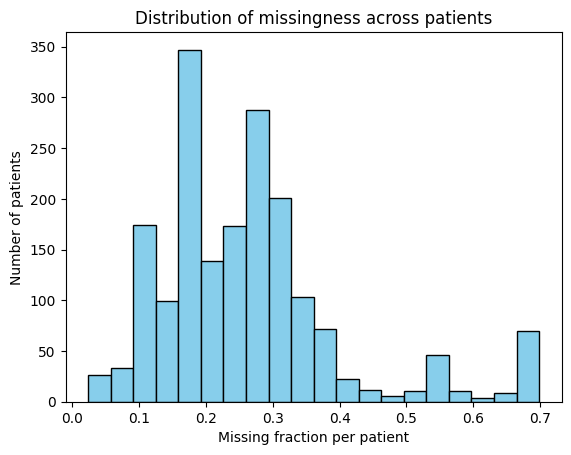

In [63]:
df['missing_fraction'] = df.isnull().mean(axis=1)   # fraction between 0 and 1
df['missing_count'] = df.isnull().sum(axis=1)

import matplotlib.pyplot as plt

plt.hist(df['missing_fraction'], bins=20, color='skyblue', edgecolor='black')
plt.xlabel('Missing fraction per patient')
plt.ylabel('Number of patients')
plt.title('Distribution of missingness across patients')
plt.show()

In [64]:
df = df[df['missing_fraction'] <= 0.2]
df.isnull().sum()

SUBJECT_ID            0
GENDER_x              0
DOD                   0
DOD_HOSP              0
anchor_year           0
                   ... 
min_diastolic_BP    150
min_mean_BP         150
min_Spo2            131
missing_fraction      0
missing_count         0
Length: 128, dtype: int64

In [65]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 681 entries, 10 to 1844
Columns: 128 entries, SUBJECT_ID to missing_count
dtypes: datetime64[ns](1), float64(93), int64(24), int8(1), object(9)
memory usage: 681.7+ KB


In [66]:
# Check if they are identical:
df['gender'] = df['GENDER_x']  # keep one
df.drop(columns=['GENDER_x', 'GENDER_y'], inplace=True)

df = df.drop(columns = ['anchor_age_x', 'anchor_age_y', 'anchor_year'])
df = df.drop(columns=['missing_fraction', 'missing_count'])
df = df.drop(columns=['DOD_HOSP'])

In [67]:
df.to_csv('mimic_iii_data.csv', index=False)

In [41]:
import pandas as pd

threshold = len(df) * 0.7

# Drop columns where non-null count < threshold
df_cleaned = df.dropna(axis=1, thresh=threshold)

# Optional: see which columns were dropped
dropped_cols = set(df.columns) - set(df_cleaned.columns)
print("Dropped columns (more than 30% missing):", dropped_cols)


Dropped columns (more than 30% missing): {'max_Heart Rate', 'mean_Hematocrit', 'max_mean_BP', 'max_diastolic_BP', 'mean_Hemoglobin', 'max_systolic_BP', 'mean_Bilirubin', 'max_Spo2', 'mean_AST', 'mean_Lactate', 'mean_Troponin', 'mean_CRP', 'mean_Albumin'}


In [42]:
df['outtime'] = pd.to_datetime(df['OUTTIME'])
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1776 entries, 0 to 1845
Data columns (total 66 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   SUBJECT_ID           1776 non-null   int64         
 1   DOD                  1776 non-null   object        
 2   DOD_HOSP             1776 non-null   object        
 3   HADM_ID              1776 non-null   int64         
 4   ICUSTAY_ID           1776 non-null   int64         
 5   FIRST_CAREUNIT       1776 non-null   object        
 6   LAST_CAREUNIT        1776 non-null   object        
 7   INTIME               1776 non-null   datetime64[ns]
 8   OUTTIME              1776 non-null   object        
 9   LOS                  1776 non-null   float64       
 10  age                  1776 non-null   float64       
 11  is_stroke            1776 non-null   int8          
 12  ETHNICITY            1776 non-null   object        
 13  pvd                  1776 non-null   i

In [43]:
#df = df.replace({True: 1, False: 0})
# Drop IDs and datetimes (models can’t use raw timestamps)

drop_cols = [c for c in ['SUBJECT_ID','HADM_ID','ICUSTAY_ID'] if c in df.columns]
df = df.drop(columns=drop_cols, errors='ignore')
dt_cols = df.select_dtypes(include=['datetime64[ns]', 'datetime64']).columns
df = df.drop(columns=list(dt_cols), errors='ignore')

In [44]:
# Target & features
y = df['is_stroke'].astype(int)
X = df.drop(columns=['is_stroke'])

X.columns = X.columns.astype(str)

# Identify categorical (object/category) vs numeric columns
cat_cols = X.select_dtypes(include=['object','category']).columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]

In [45]:
for c in cat_cols:
    X[c] = X[c].astype('category').cat.codes  # -1 marks missing categories

# Categorical column indices (relative to X’s current column order)
cat_idx = [X.columns.get_loc(c) for c in cat_cols]

In [46]:
def encode_categoricals(train_df, val_df, cat_columns):
    train_enc = train_df.copy()
    val_enc = val_df.copy()
    for c in cat_columns:
        # Build mapping from TRAIN
        cats = train_enc[c].astype('category').cat.categories
        mapping = {k: i for i, k in enumerate(cats)}
        # Map train/val; unknowns in val -> -1
        train_enc[c] = train_enc[c].map(mapping).astype('Int64')
        val_enc[c]   = val_enc[c].map(mapping).fillna(-1).astype('Int64')
    return train_enc, val_enc

In [47]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# 5) Models
# -----------------------------
models = {
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(kernel='rbf', probability=True, random_state=42),
    "MLP": MLPClassifier(hidden_layer_sizes=(32,16), max_iter=200, random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=500, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "XGBoost": XGBClassifier(
        use_label_encoder=False, eval_metric='logloss',
        n_estimators=150, random_state=42
    )
}

In [48]:
from sklearn.model_selection import StratifiedKFold
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTENC
from sklearn.metrics import roc_curve, auc, roc_auc_score


# Storage for results
fold_auc = {name: [] for name in models.keys()}
# For mean ROC plotting
mean_fpr = np.linspace(0, 1, 1001)
roc_curves = {name: [] for name in models.keys()}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y), start=1):
    X_tr_raw, X_va_raw = X.iloc[train_idx].copy(), X.iloc[val_idx].copy()
    y_tr, y_va = y.iloc[train_idx].copy(), y.iloc[val_idx].copy()

    # 1) Encode categoricals (train mapping -> apply to val)
    X_tr_cat, X_va_cat = encode_categoricals(X_tr_raw, X_va_raw, cat_cols)

    # 2) Iterative SVD imputation (fit on train, transform both)
    imputer = IterativeImputer(random_state=42, max_iter=10)
    X_tr_imp = pd.DataFrame(imputer.fit_transform(X_tr_cat), columns=X.columns)
    X_va_imp = pd.DataFrame(imputer.transform(X_va_cat),    columns=X.columns)

    # Categorical cols became floats after imputation; round back to ints
    for c in cat_cols:
        X_tr_imp[c] = np.rint(X_tr_imp[c]).astype(int)
        X_va_imp[c] = np.rint(X_va_imp[c]).astype(int)

    # 3) Scale ONLY numeric columns (fit on train numeric)
    scaler = StandardScaler()
    X_tr_proc = X_tr_imp.copy()
    X_va_proc = X_va_imp.copy()

    # make sure keys match current column dtype (strings)
    num_cols_str = [str(c) for c in num_cols if c in X_tr_proc.columns]
    if num_cols_str:
        X_tr_proc[num_cols_str] = scaler.fit_transform(X_tr_imp[num_cols_str])
        X_va_proc[num_cols_str] = scaler.transform(X_va_imp[num_cols_str])

    # 4) SMOTENC on TRAIN only
    # Build categorical indices relative to current column order
    cat_idx = [X_tr_proc.columns.get_loc(c) for c in cat_cols if c in X_tr_proc.columns]
    smote_nc = SMOTENC(categorical_features=cat_idx, random_state=42)
    X_tr_bal, y_tr_bal = smote_nc.fit_resample(X_tr_proc.values, y_tr.values)

    # 5) Train models & collect ROC/AUC on validation fold
    for name, model in models.items():
        model.fit(X_tr_bal, y_tr_bal)
        y_prob = model.predict_proba(X_va_proc.values)[:, 1]
        fpr, tpr, _ = roc_curve(y_va, y_prob)
        roc_auc = auc(fpr, tpr)
        fold_auc[name].append(roc_auc)

        # interpolate TPR on a common FPR grid for mean ROC later
        interp_tpr = np.interp(mean_fpr, fpr, tpr)
        interp_tpr[0] = 0.0
        roc_curves[name].append(interp_tpr)

    print(f"Fold {fold} done.")

/home1/bingi/.local/lib/python3.13/site-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
/home1/bingi/.local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home1/bingi/.local/lib/python3.13/site-packages/xgboost/training.py:183: UserWarning: [17:30:33] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=

Fold 1 done.


/home1/bingi/.local/lib/python3.13/site-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
/home1/bingi/.local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home1/bingi/.local/lib/python3.13/site-packages/xgboost/training.py:183: UserWarning: [17:30:41] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=

Fold 2 done.


/home1/bingi/.local/lib/python3.13/site-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
/home1/bingi/.local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home1/bingi/.local/lib/python3.13/site-packages/xgboost/training.py:183: UserWarning: [17:30:48] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=

...

/home1/bingi/.local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home1/bingi/.local/lib/python3.13/site-packages/xgboost/training.py:183: UserWarning: [17:30:54] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Fold 4 done.


/home1/bingi/.local/lib/python3.13/site-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
/home1/bingi/.local/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Fold 5 done.


/home1/bingi/.local/lib/python3.13/site-packages/xgboost/training.py:183: UserWarning: [17:31:01] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


In [30]:
print("\nAUC (5-fold CV):")
for name in models.keys():
    a = np.array(fold_auc[name])
    print(f"{name:20s} mean={a.mean():.3f}  std={a.std(ddof=1):.003f}  folds={np.round(a,3)}")


AUC (5-fold CV):


NameError: name 'models' is not defined

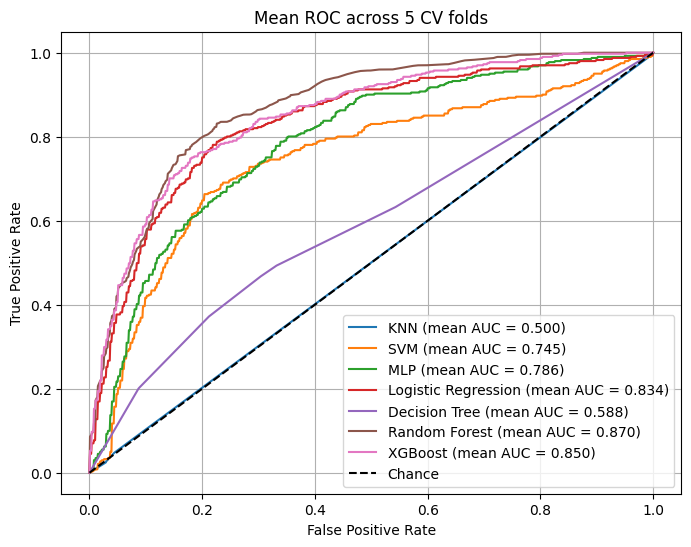

In [50]:
plt.figure(figsize=(8,6))
for name in models.keys():
    tprs = np.vstack(roc_curves[name])
    mean_tpr = tprs.mean(axis=0)
    std_tpr  = tprs.std(axis=0, ddof=1)
    mean_auc = auc(mean_fpr, mean_tpr)

    plt.plot(mean_fpr, mean_tpr, label=f"{name} (mean AUC = {mean_auc:.3f})")
    # Optional band:
    # plt.fill_between(mean_fpr, np.maximum(mean_tpr-std_tpr, 0), np.minimum(mean_tpr+std_tpr,1), alpha=0.1)

plt.plot([0,1],[0,1],'k--',label='Chance')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Mean ROC across 5 CV folds")
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

/tmp/SLURM_4699154/ipykernel_255806/2784888172.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


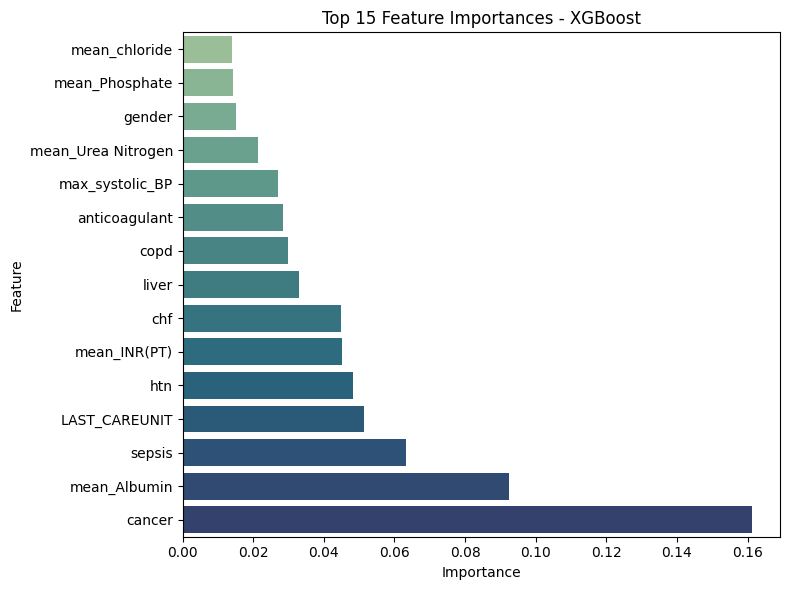

In [51]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.inspection import permutation_importance

# Choose models that provide feature importances directly
importance_models = {
    #"Random Forest": models["Random Forest"],
    #"Decision Tree": models["Decision Tree"],
    "XGBoost": models["XGBoost"],
    #"Logistic Regression": models["Logistic Regression"]
}

for name, model in importance_models.items():
    if hasattr(model, "feature_importances_"):
        # Tree-based models
        importances = model.feature_importances_
    elif hasattr(model, "coef_"):
        # Logistic regression
        importances = np.abs(model.coef_[0])
    else:
        continue

    # Sort top 15 important features
    indices = np.argsort(importances)[-15:]
    plt.figure(figsize=(8,6))
    sns.barplot(
        x=importances[indices],
        y=np.array(X.columns)[indices],
        palette="crest"
    )
    plt.title(f"Top 15 Feature Importances - {name}")
    plt.xlabel("Importance")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()

/home1/bingi/.local/lib/python3.13/site-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
/home1/bingi/.local/lib/python3.13/site-packages/xgboost/training.py:183: UserWarning: [17:31:05] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/home1/bingi/.local/lib/python3.13/site-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
/home1/bingi/.local/lib/python3.13/site-packages/xgboost/training.py:183: UserWarning: [17:31:09] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/home1/bingi/.local/lib/python3.13/site-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
/

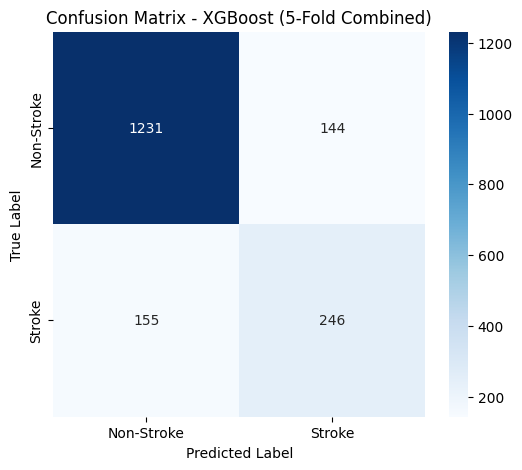

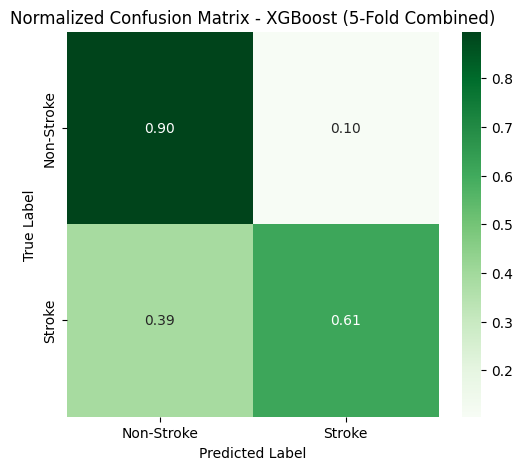

Classification Report (5-Fold Combined):
              precision    recall  f1-score   support

  Non-Stroke       0.89      0.90      0.89      1375
      Stroke       0.63      0.61      0.62       401

    accuracy                           0.83      1776
   macro avg       0.76      0.75      0.76      1776
weighted avg       0.83      0.83      0.83      1776



In [52]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Store predictions across all folds
all_y_true = []
all_y_pred = []

# Rerun CV for the chosen model (XGBoost)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
xgb_model = XGBClassifier(
    use_label_encoder=False, eval_metric='logloss',
    n_estimators=150, random_state=42
)

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y), start=1):
    X_tr_raw, X_va_raw = X.iloc[train_idx].copy(), X.iloc[val_idx].copy()
    y_tr, y_va = y.iloc[train_idx], y.iloc[val_idx]

    # Encode categoricals using your helper
    X_tr_cat, X_va_cat = encode_categoricals(X_tr_raw, X_va_raw, cat_cols)

    # Imputation
    imputer = IterativeImputer(random_state=42, max_iter=10)
    X_tr_imp = pd.DataFrame(imputer.fit_transform(X_tr_cat), columns=X.columns)
    X_va_imp = pd.DataFrame(imputer.transform(X_va_cat), columns=X.columns)

    for c in cat_cols:
        X_tr_imp[c] = np.rint(X_tr_imp[c]).astype(int)
        X_va_imp[c] = np.rint(X_va_imp[c]).astype(int)

    # Scale numeric columns
    scaler = StandardScaler()
    num_cols_str = [str(c) for c in num_cols if c in X_tr_imp.columns]
    X_tr_proc, X_va_proc = X_tr_imp.copy(), X_va_imp.copy()
    if num_cols_str:
        X_tr_proc[num_cols_str] = scaler.fit_transform(X_tr_imp[num_cols_str])
        X_va_proc[num_cols_str] = scaler.transform(X_va_imp[num_cols_str])

    # SMOTENC on training fold only
    cat_idx = [X_tr_proc.columns.get_loc(c) for c in cat_cols if c in X_tr_proc.columns]
    smote_nc = SMOTENC(categorical_features=cat_idx, random_state=42)
    X_tr_bal, y_tr_bal = smote_nc.fit_resample(X_tr_proc.values, y_tr.values)

    # Train and predict on validation fold
    xgb_model.fit(X_tr_bal, y_tr_bal)
    y_pred_fold = xgb_model.predict(X_va_proc.values)

    # Collect true and predicted labels
    all_y_true.extend(y_va)
    all_y_pred.extend(y_pred_fold)

# -------------------------------
# Compute overall confusion matrix
# -------------------------------
cm = confusion_matrix(all_y_true, all_y_pred)
cm_norm = confusion_matrix(all_y_true, all_y_pred, normalize='true')

# Plot raw counts
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Non-Stroke', 'Stroke'],
            yticklabels=['Non-Stroke', 'Stroke'])
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - XGBoost (5-Fold Combined)")
plt.show()


# Print metrics
print("Classification Report (5-Fold Combined):")
print(classification_report(all_y_true, all_y_pred, target_names=["Non-Stroke", "Stroke"]))

/home1/bingi/.local/lib/python3.13/site-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
/home1/bingi/.local/lib/python3.13/site-packages/xgboost/training.py:183: UserWarning: [17:31:23] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/home1/bingi/.local/lib/python3.13/site-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
/home1/bingi/.local/lib/python3.13/site-packages/xgboost/training.py:183: UserWarning: [17:31:27] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/home1/bingi/.local/lib/python3.13/site-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
/

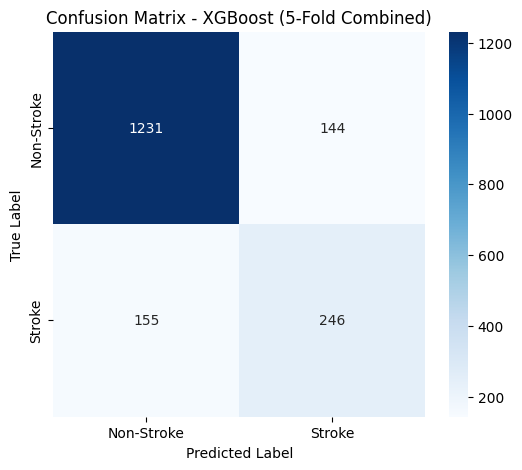

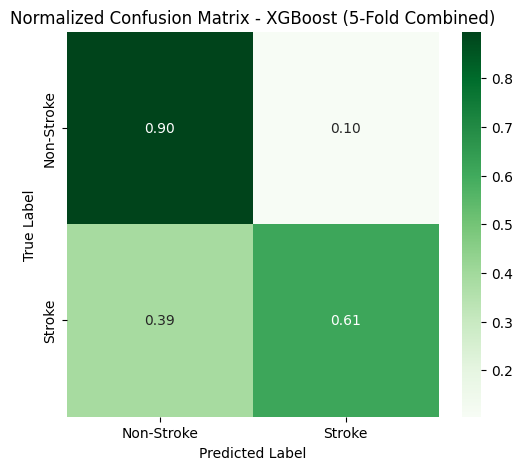

Classification Report (5-Fold Combined):
              precision    recall  f1-score   support

  Non-Stroke       0.89      0.90      0.89      1375
      Stroke       0.63      0.61      0.62       401

    accuracy                           0.83      1776
   macro avg       0.76      0.75      0.76      1776
weighted avg       0.83      0.83      0.83      1776



In [53]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Store predictions across all folds
all_y_true = []
all_y_pred = []

# Rerun CV for the chosen model (XGBoost)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
xgb_model = XGBClassifier(
    use_label_encoder=False, eval_metric='logloss',
    n_estimators=150, random_state=42
)

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y), start=1):
    X_tr_raw, X_va_raw = X.iloc[train_idx].copy(), X.iloc[val_idx].copy()
    y_tr, y_va = y.iloc[train_idx], y.iloc[val_idx]

    # Encode categoricals using your helper
    X_tr_cat, X_va_cat = encode_categoricals(X_tr_raw, X_va_raw, cat_cols)

    # Imputation
    imputer = IterativeImputer(random_state=42, max_iter=10)
    X_tr_imp = pd.DataFrame(imputer.fit_transform(X_tr_cat), columns=X.columns)
    X_va_imp = pd.DataFrame(imputer.transform(X_va_cat), columns=X.columns)

    for c in cat_cols:
        X_tr_imp[c] = np.rint(X_tr_imp[c]).astype(int)
        X_va_imp[c] = np.rint(X_va_imp[c]).astype(int)

    # Scale numeric columns
    scaler = StandardScaler()
    num_cols_str = [str(c) for c in num_cols if c in X_tr_imp.columns]
    X_tr_proc, X_va_proc = X_tr_imp.copy(), X_va_imp.copy()
    if num_cols_str:
        X_tr_proc[num_cols_str] = scaler.fit_transform(X_tr_imp[num_cols_str])
        X_va_proc[num_cols_str] = scaler.transform(X_va_imp[num_cols_str])

    # SMOTENC on training fold only
    cat_idx = [X_tr_proc.columns.get_loc(c) for c in cat_cols if c in X_tr_proc.columns]
    smote_nc = SMOTENC(categorical_features=cat_idx, random_state=42)
    X_tr_bal, y_tr_bal = smote_nc.fit_resample(X_tr_proc.values, y_tr.values)

    # Train and predict on validation fold
    xgb_model.fit(X_tr_bal, y_tr_bal)
    y_pred_fold = xgb_model.predict(X_va_proc.values)

    # Collect true and predicted labels
    all_y_true.extend(y_va)
    all_y_pred.extend(y_pred_fold)

# -------------------------------
# Compute overall confusion matrix
# -------------------------------
cm = confusion_matrix(all_y_true, all_y_pred)
cm_norm = confusion_matrix(all_y_true, all_y_pred, normalize='true')

# Plot raw counts
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Non-Stroke', 'Stroke'],
            yticklabels=['Non-Stroke', 'Stroke'])
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - XGBoost (5-Fold Combined)")
plt.show()

# Plot normalized
plt.figure(figsize=(6,5))
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Greens',
            xticklabels=['Non-Stroke', 'Stroke'],
            yticklabels=['Non-Stroke', 'Stroke'])
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Normalized Confusion Matrix - XGBoost (5-Fold Combined)")
plt.show()

# Print metrics
print("Classification Report (5-Fold Combined):")
print(classification_report(all_y_true, all_y_pred, target_names=["Non-Stroke", "Stroke"]))